# 05 - Jacobian modes versus specimen thickness

On the thin cached hBN object the leading Jacobian modes were pure probe optics: the
object changed the operator by only 6-10% in Frobenius norm and the leading mode
subspace matched the vacuum one to $\cos = 1.0000$. The cause was that the object is a
**weak phase object**, $|O_0 - 1|_{\max} = 0.197$. Amplifying the phase artificially
broke that, which suggests a real thick specimen should too.

This notebook builds hBN slabs of increasing thickness from scratch with abTEM,
propagates a probe through them by **multislice**, and recomputes the Jacobian modes at
each thickness.

## What the Jacobian means once the specimen is thick

For a single projected phase object the exit wave is $\psi_0 = P_R O_0$ and a phase
perturbation of the object is the same thing as a phase perturbation of the exit wave.
That is no longer true through a thick specimen: an atom displaced at depth is not
equivalent to any multiplicative phase screen at the exit plane.

What stays exactly well defined is the operator itself. The Jacobian

$$A_R h = -2\,\mathrm{Im}\!\left[\overline{\Psi_{0,R}}\;\mathrm{crop}\,\mathcal{F}\{\psi_{0,R} h\}\right],
\qquad \Psi_{0,R} = \mathrm{crop}\,\mathcal{F}\{\psi_{0,R}\}$$

depends only on $\psi_{0,R}$ and $\Psi_{0,R}$, never on how $\psi_{0,R}$ was produced. So
feeding it the **multislice** exit wave gives the exact Jacobian of the measurement with
respect to a phase perturbation **applied at the exit plane**:

$$\psi_1 = \psi_0\,e^{ih}.$$

That is the quantity computed below, and it is what the modes describe. For a thin
specimen it coincides with perturbing the object. For a thick one it does not, and this
notebook does **not** answer "which displacement of an atom at depth is most visible" -
that needs the chain rule through the slices and is a different calculation.

What it does answer, correctly, is whether a strongly scattering specimen stops the
Jacobian from being a property of the probe alone.

**Limitations:** static lattice, no frozen phonons, no absorption, a single probe
position at the centre of the cell, and a periodic cell so the slab is laterally
infinite.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from ase import Atoms

import abtem
from abtem import Probe, Potential, PixelatedDetector

NOTEBOOK_DIR = Path.cwd()
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import linearized_jacobian as lj

print("abtem   :", abtem.__version__)
print("module  :", lj.__file__)

abtem   : 1.0.10
module  : /home/rotem/ptycho_light/quantem/scripts/linearized-ptycho/linearized_jacobian.py


## Configuration

In [2]:
HBN_LATTICE_CONSTANT_ANG = 2.504        # in-plane a
HBN_INTERLAYER_SPACING_ANG = 3.33       # AA' stacking
SUPERCELL_REPEATS = (10, 6)             # in-plane, aiming for a ~25 A cell
VACUUM_PADDING_ANG = 4.0

LAYER_COUNT_SWEEP = [1, 2, 4, 8, 16, 32]

ACC_VOLTAGE_EV = 60e3
PROBE_SEMIANGLE_MRAD = 30.0
PROBE_DEFOCUS_ANG = 0.0
POTENTIAL_SAMPLING_ANG = 0.096
POTENTIAL_SLICE_THICKNESS_ANG = HBN_INTERLAYER_SPACING_ANG / 2
POTENTIAL_PARAMETRIZATION = "lobato"

N_MODES = 4
MODE_VIEW_HALFWIDTH_ANG = 6.0
RANDOM_SEED = 0

print("layer sweep        :", LAYER_COUNT_SWEEP)
print("thicknesses [A]    :",
      [round(n * HBN_INTERLAYER_SPACING_ANG, 2) for n in LAYER_COUNT_SWEEP])
print("semiangle [mrad]   :", PROBE_SEMIANGLE_MRAD)
print("slice thickness [A]:", POTENTIAL_SLICE_THICKNESS_ANG)

layer sweep        : [1, 2, 4, 8, 16, 32]
thicknesses [A]    : [3.33, 6.66, 13.32, 26.64, 53.28, 106.56]
semiangle [mrad]   : 30.0
slice thickness [A]: 1.665


## Build the hBN slabs

AA' stacked hexagonal hBN, orthogonalized and repeated in plane, then cut to an exact
number of layers.

In [3]:
hbn_two_layer_cell = Atoms(
    symbols="BNNB",
    scaled_positions=[(0, 0, 0), (1/3, 2/3, 0), (0, 0, 0.5), (1/3, 2/3, 0.5)],
    cell=[
        (HBN_LATTICE_CONSTANT_ANG, 0, 0),
        (-HBN_LATTICE_CONSTANT_ANG / 2, HBN_LATTICE_CONSTANT_ANG * np.sqrt(3) / 2, 0),
        (0, 0, 2 * HBN_INTERLAYER_SPACING_ANG),
    ],
    pbc=True,
)
hbn_orthogonal_cell = abtem.orthogonalize_cell(hbn_two_layer_cell)


def build_hbn_slab(n_layers):
    # Repeat enough z-periods to cover n_layers, then cut back to exactly n_layers.
    slab = hbn_orthogonal_cell * (
        SUPERCELL_REPEATS[0], SUPERCELL_REPEATS[1], max(1, int(np.ceil(n_layers / 2)))
    )
    layer_z_ang = np.sort(np.unique(slab.positions[:, 2].round(3)))
    cutoff_z_ang = layer_z_ang[min(n_layers, len(layer_z_ang)) - 1]
    slab = slab[slab.positions[:, 2].round(3) <= cutoff_z_ang + 1e-6]
    slab.cell[2, 2] = n_layers * HBN_INTERLAYER_SPACING_ANG + VACUUM_PADDING_ANG
    return slab


print("orthogonal unit cell [A]:", hbn_orthogonal_cell.cell.cellpar().round(3))
reference_slab = build_hbn_slab(1)
print("supercell in plane [A]  :",
      round(float(reference_slab.cell[0, 0]), 3), "x",
      round(float(reference_slab.cell[1, 1]), 3))
print(f"{'layers':>7} {'thickness [A]':>14} {'atoms':>7}")
for n_layers in LAYER_COUNT_SWEEP:
    slab = build_hbn_slab(n_layers)
    print(f"{n_layers:7d} {n_layers * HBN_INTERLAYER_SPACING_ANG:14.2f} {len(slab):7d}")

orthogonal unit cell [A]: [ 2.504  4.337  6.66  90.    90.    90.   ]
supercell in plane [A]  : 25.04 x 26.022
 layers  thickness [A]   atoms
      1           3.33     240
      2           6.66     480
      4          13.32     960
      8          26.64    1920
     16          53.28    3840
     32         106.56    7680


## Propagate and compute the modes

For each thickness: build the potential, run multislice to the exit plane, form
$\Psi_0 = \mathrm{crop}\,\mathcal{F}\{\psi_0\}$, and check it against what abTEM's own
detector reports. That check is the premise of everything below - if $|\Psi_0|^2$ is not
the measured intensity then the Jacobian is not the Jacobian of this measurement.

The vacuum reference at each thickness is the bare probe, which is what the modes would
be if the specimen did nothing.

In [4]:
sweep = []
start_time = time.time()
for n_layers in LAYER_COUNT_SWEEP:
    slab = build_hbn_slab(n_layers)
    potential = Potential(
        slab, sampling=POTENTIAL_SAMPLING_ANG,
        slice_thickness=POTENTIAL_SLICE_THICKNESS_ANG,
        projection="infinite", parametrization=POTENTIAL_PARAMETRIZATION,
    )
    probe = Probe(energy=ACC_VOLTAGE_EV, semiangle_cutoff=PROBE_SEMIANGLE_MRAD,
                  defocus=PROBE_DEFOCUS_ANG)
    probe.match_grid(potential)
    probe_position_ang = [potential.extent[0] / 2, potential.extent[1] / 2]
    detector_shape = lj.valid_detector_shape(probe)

    exit_wave = np.asarray(
        probe.multislice(potential, scan=probe_position_ang).compute().array
    ).astype(np.complex64)
    camera_wave = lj.camera_wave_from_exit_wave(exit_wave, detector_shape)

    # premise check against abTEM's own detector
    measured = np.asarray(
        probe.scan(potential, scan=probe_position_ang,
                   detectors=PixelatedDetector(max_angle="valid")).compute().array
    ).astype(np.float64).squeeze()
    model_intensity = np.abs(camera_wave) ** 2
    detector_agreement = float(
        np.abs(model_intensity - measured).max() / measured.max()
    )

    probe_realspace = np.asarray(
        probe.build(scan=probe_position_ang).compute().array
    ).astype(np.complex64)
    object_strength = float(
        np.linalg.norm(exit_wave - probe_realspace) / np.linalg.norm(probe_realspace)
    )

    object_modes, singular_values = lj.leading_jacobian_object_modes(
        exit_wave, camera_wave, detector_shape, n_modes=N_MODES, seed=RANDOM_SEED)
    vacuum_modes, vacuum_singular_values = lj.leading_jacobian_object_modes(
        probe_realspace, lj.camera_wave_from_exit_wave(probe_realspace, detector_shape),
        detector_shape, n_modes=N_MODES, seed=RANDOM_SEED)
    object_basis = np.linalg.qr(object_modes.reshape(N_MODES, -1).T)[0]
    vacuum_basis = np.linalg.qr(vacuum_modes.reshape(N_MODES, -1).T)[0]
    subspace_cosines = np.linalg.svd(object_basis.T @ vacuum_basis, compute_uv=False)

    projected_phase = (np.asarray(potential.build().compute().array).sum(0)
                       * float(abtem.core.energy.energy2sigma(ACC_VOLTAGE_EV)))

    sweep.append(dict(
        n_layers=n_layers,
        thickness_ang=n_layers * HBN_INTERLAYER_SPACING_ANG,
        n_atoms=len(slab),
        n_slices=potential.num_slices,
        detector_shape=detector_shape,
        exit_wave=exit_wave,
        probe_realspace=probe_realspace,
        projected_phase_rad=projected_phase,
        projected_phase_max_rad=float(projected_phase.max()),
        object_strength=object_strength,
        detector_agreement=detector_agreement,
        object_modes=object_modes,
        singular_values=singular_values,
        vacuum_singular_values=vacuum_singular_values,
        subspace_cosines=subspace_cosines,
        extent_ang=(float(potential.extent[0]), float(potential.extent[1])),
    ))
    print(f"{n_layers:3d} layers ({sweep[-1]['thickness_ang']:6.2f} A, "
          f"{potential.num_slices:3d} slices)  "
          f"phase_max = {projected_phase.max():6.3f} rad  "
          f"||exit-probe||/||probe|| = {object_strength:5.3f}  "
          f"detector check = {detector_agreement:.1e}  "
          f"min subspace cos = {subspace_cosines.min():.4f}")
print(f"\ntotal {time.time() - start_time:.1f} s")

  1 layers (  3.33 A,   5 slices)  phase_max =  0.497 rad  ||exit-probe||/||probe|| = 0.181  detector check = 5.2e-07  min subspace cos = 0.9984
  2 layers (  6.66 A,   7 slices)  phase_max =  0.919 rad  ||exit-probe||/||probe|| = 0.244  detector check = 5.1e-07  min subspace cos = 0.0000
  4 layers ( 13.32 A,  11 slices)  phase_max =  1.838 rad  ||exit-probe||/||probe|| = 0.373  detector check = 4.1e-07  min subspace cos = 0.0000
  8 layers ( 26.64 A,  19 slices)  phase_max =  3.676 rad  ||exit-probe||/||probe|| = 0.588  detector check = 4.3e-07  min subspace cos = 0.0004
 16 layers ( 53.28 A,  35 slices)  phase_max =  7.351 rad  ||exit-probe||/||probe|| = 0.885  detector check = 2.9e-07  min subspace cos = 0.0003
 32 layers (106.56 A,  67 slices)  phase_max = 14.703 rad  ||exit-probe||/||probe|| = 1.237  detector check = 3.5e-07  min subspace cos = 0.0023

total 14.3 s


In [5]:
worst_agreement = max(entry["detector_agreement"] for entry in sweep)
print(f"worst |crop F(psi_0)|^2 vs abTEM detector over the sweep: {worst_agreement:.2e}")
assert worst_agreement < 1e-4, "camera wave does not reproduce the measured intensity"
print("premise holds: Psi_0 is the measured amplitude at every thickness")

worst |crop F(psi_0)|^2 vs abTEM detector over the sweep: 5.17e-07
premise holds: Psi_0 is the measured amplitude at every thickness


## The modes

Rows are thickness, columns are $v_1 \ldots v_4$. Grey contours are the projected
potential of that slab, so if the modes have acquired the lattice it shows as mode
structure tracking the atom positions.

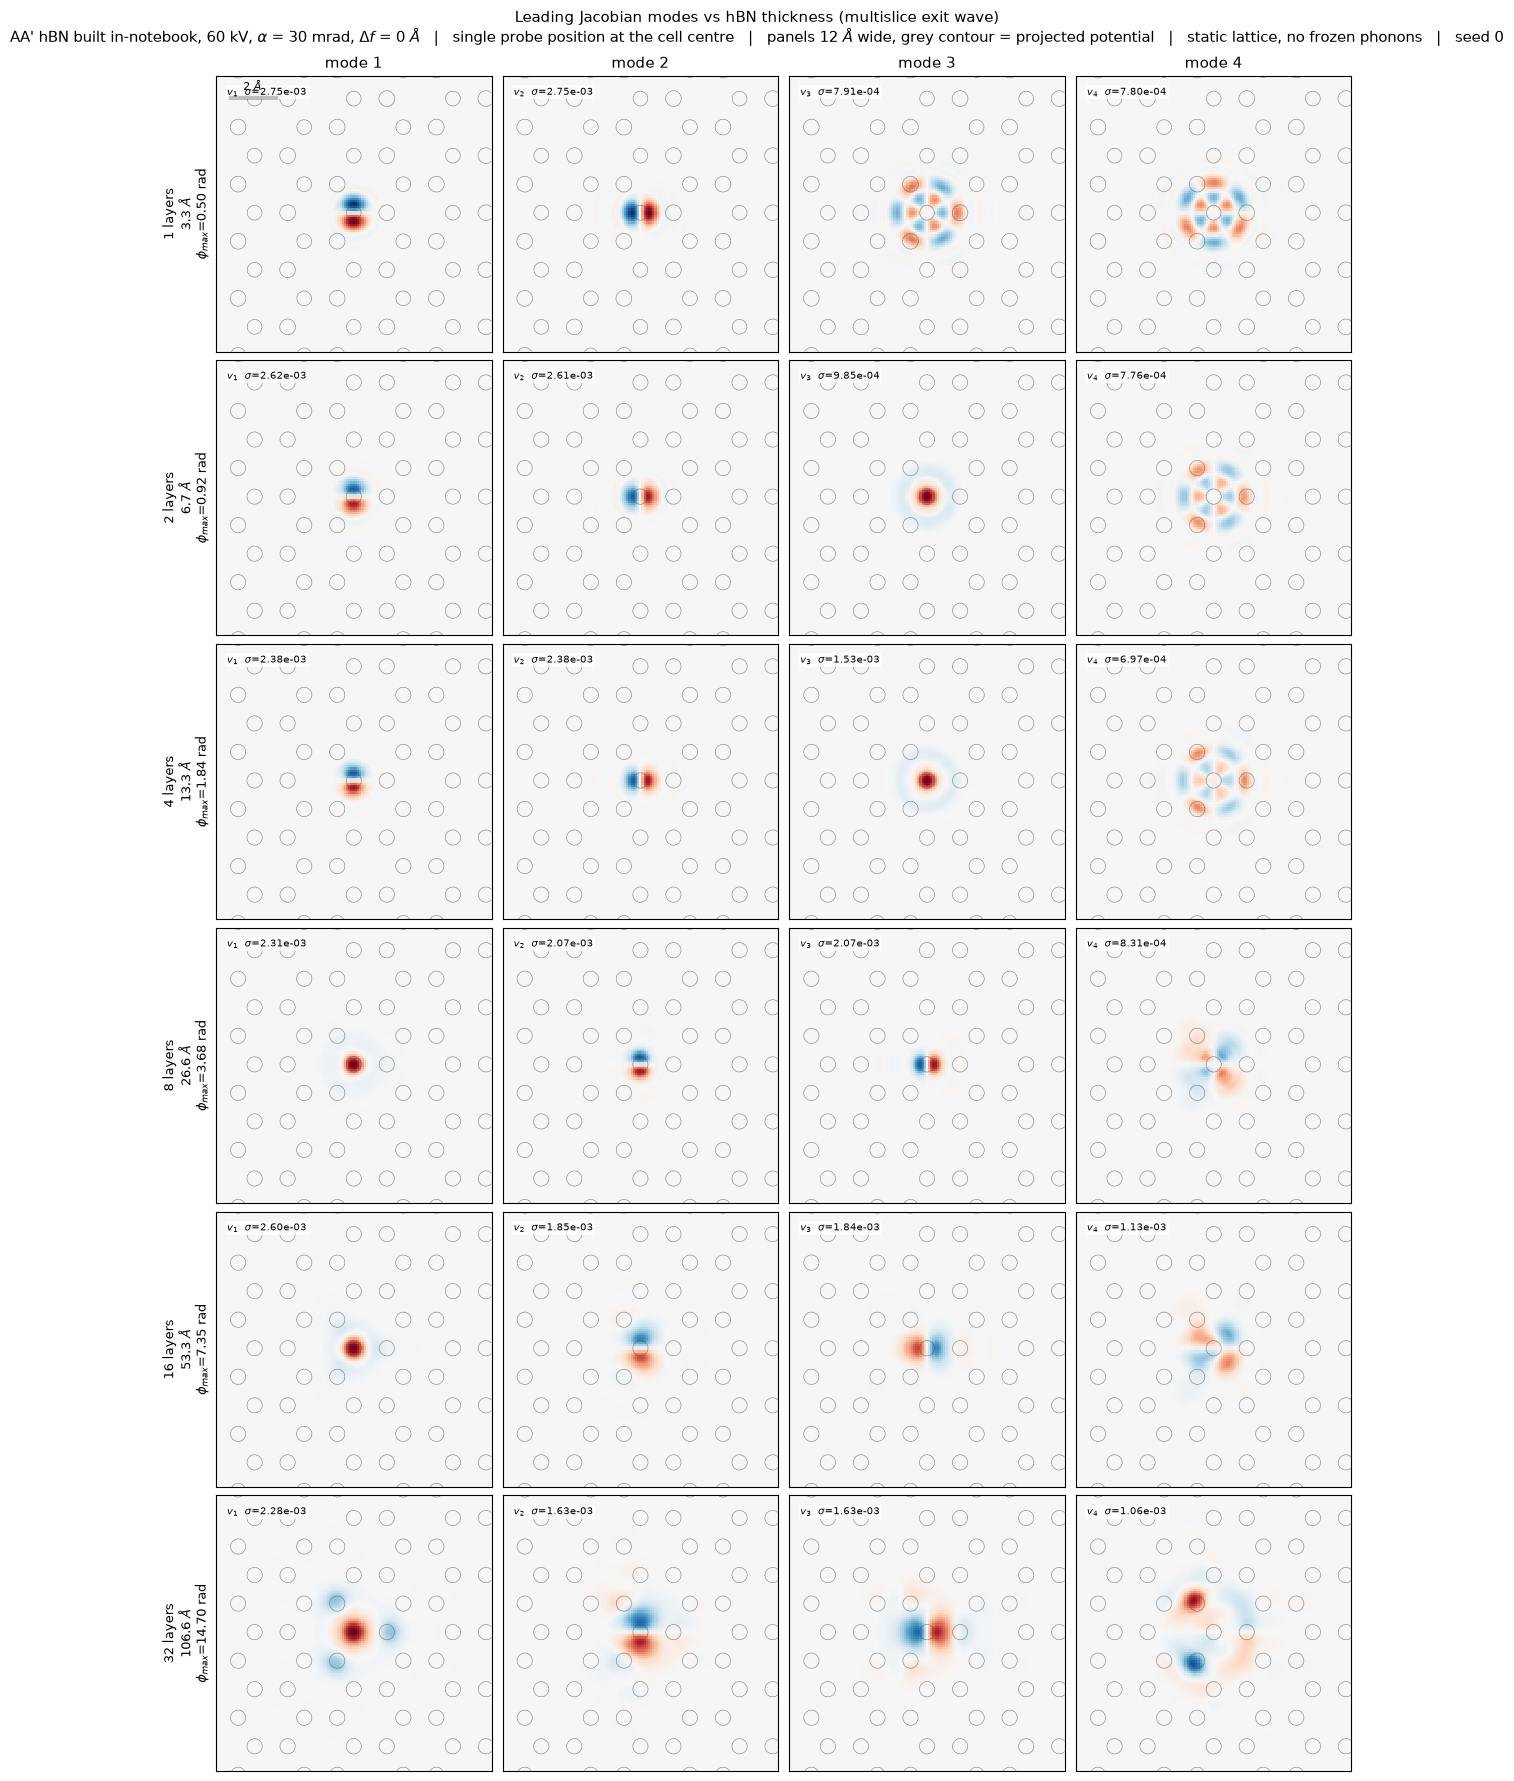

In [6]:
n_rows = len(sweep)
fig, axes = plt.subplots(
    n_rows, N_MODES, figsize=(3.0 * N_MODES, 2.95 * n_rows), constrained_layout=True
)
for row, entry in enumerate(sweep):
    sampling_ang = entry["extent_ang"][0] / entry["exit_wave"].shape[0]
    half_px = int(round(MODE_VIEW_HALFWIDTH_ANG / sampling_ang))
    centre_row = entry["exit_wave"].shape[0] // 2
    centre_col = entry["exit_wave"].shape[1] // 2
    rows = slice(centre_row - half_px, centre_row + half_px + 1)
    cols = slice(centre_col - half_px, centre_col + half_px + 1)
    view_extent = [-MODE_VIEW_HALFWIDTH_ANG, MODE_VIEW_HALFWIDTH_ANG] * 2
    phase_patch = entry["projected_phase_rad"][rows, cols]
    contour_level = np.percentile(phase_patch, 88.0)

    shared_vmax = float(np.abs(entry["object_modes"][:, rows, cols]).max())
    for column in range(N_MODES):
        ax = axes[row, column]
        ax.imshow(
            entry["object_modes"][column][rows, cols], extent=view_extent,
            origin="lower", cmap="RdBu_r", vmin=-shared_vmax, vmax=shared_vmax,
            interpolation="nearest",
        )
        ax.contour(
            np.linspace(view_extent[0], view_extent[1], phase_patch.shape[1]),
            np.linspace(view_extent[2], view_extent[3], phase_patch.shape[0]),
            phase_patch, levels=[contour_level], colors="0.30",
            linewidths=0.45, alpha=0.65,
        )
        ax.set_xticks([])
        ax.set_yticks([])
        ax.text(0.04, 0.96,
                f"$v_{column + 1}$  $\\sigma$={entry['singular_values'][column]:.2e}",
                transform=ax.transAxes, va="top", ha="left", fontsize=7.5,
                bbox=dict(facecolor="white", alpha=0.75, edgecolor="none", pad=1.2))
        if row == 0:
            ax.set_title(f"mode {column + 1}", fontsize=11)
    axes[row, 0].set_ylabel(
        f"{entry['n_layers']} layers\n{entry['thickness_ang']:.1f} $\\AA$\n"
        f"$\\phi_{{max}}$={entry['projected_phase_max_rad']:.2f} rad",
        fontsize=9,
    )

scale_bar_ang = 2.0
axes[0, 0].plot([-MODE_VIEW_HALFWIDTH_ANG + 0.6, -MODE_VIEW_HALFWIDTH_ANG + 0.6 + scale_bar_ang],
                [MODE_VIEW_HALFWIDTH_ANG - 0.9] * 2, color="black", linewidth=2.5)
axes[0, 0].text(-MODE_VIEW_HALFWIDTH_ANG + 0.6 + scale_bar_ang / 2,
                MODE_VIEW_HALFWIDTH_ANG - 0.75, f"{scale_bar_ang:.0f} $\\AA$",
                ha="center", va="bottom", fontsize=8)
fig.suptitle(
    f"Leading Jacobian modes vs hBN thickness (multislice exit wave)\n"
    f"AA' hBN built in-notebook, {ACC_VOLTAGE_EV/1e3:.0f} kV, "
    f"$\\alpha$ = {PROBE_SEMIANGLE_MRAD:.0f} mrad, $\\Delta f$ = {PROBE_DEFOCUS_ANG:.0f} $\\AA$   |   "
    f"single probe position at the cell centre   |   panels "
    f"{2*MODE_VIEW_HALFWIDTH_ANG:.0f} $\\AA$ wide, grey contour = projected potential   |   "
    f"static lattice, no frozen phonons   |   seed {RANDOM_SEED}",
    fontsize=10.5,
)
plt.show()

## The exit wave behind those modes

A mode figure can look structured while the wave behind it is wrong. Amplitude and
phase of the multislice exit wave at each thickness, same crop.

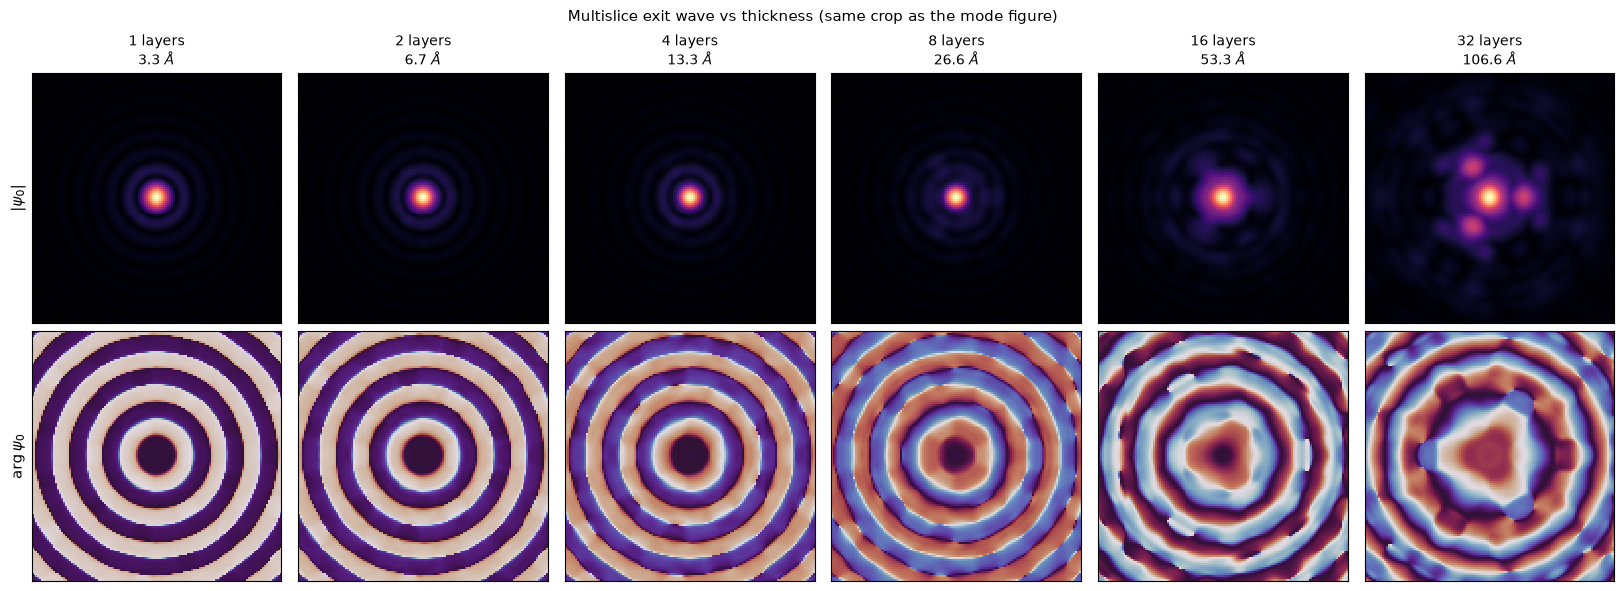

In [7]:
fig, axes = plt.subplots(2, n_rows, figsize=(2.7 * n_rows, 5.8), constrained_layout=True)
for column, entry in enumerate(sweep):
    sampling_ang = entry["extent_ang"][0] / entry["exit_wave"].shape[0]
    half_px = int(round(MODE_VIEW_HALFWIDTH_ANG / sampling_ang))
    centre_row = entry["exit_wave"].shape[0] // 2
    centre_col = entry["exit_wave"].shape[1] // 2
    patch = entry["exit_wave"][centre_row - half_px:centre_row + half_px + 1,
                               centre_col - half_px:centre_col + half_px + 1]
    view_extent = [-MODE_VIEW_HALFWIDTH_ANG, MODE_VIEW_HALFWIDTH_ANG] * 2
    axes[0, column].imshow(np.abs(patch), extent=view_extent, origin="lower",
                           cmap="magma", interpolation="nearest")
    axes[1, column].imshow(np.angle(patch), extent=view_extent, origin="lower",
                           cmap="twilight", vmin=-np.pi, vmax=np.pi,
                           interpolation="nearest")
    axes[0, column].set_title(
        f"{entry['n_layers']} layers\n{entry['thickness_ang']:.1f} $\\AA$", fontsize=10)
    for row in (0, 1):
        axes[row, column].set_xticks([])
        axes[row, column].set_yticks([])
axes[0, 0].set_ylabel("$|\\psi_0|$", fontsize=11)
axes[1, 0].set_ylabel("$\\arg\\psi_0$", fontsize=11)
fig.suptitle("Multislice exit wave vs thickness (same crop as the mode figure)",
             fontsize=11)
plt.show()

## Does the specimen take over the modes?

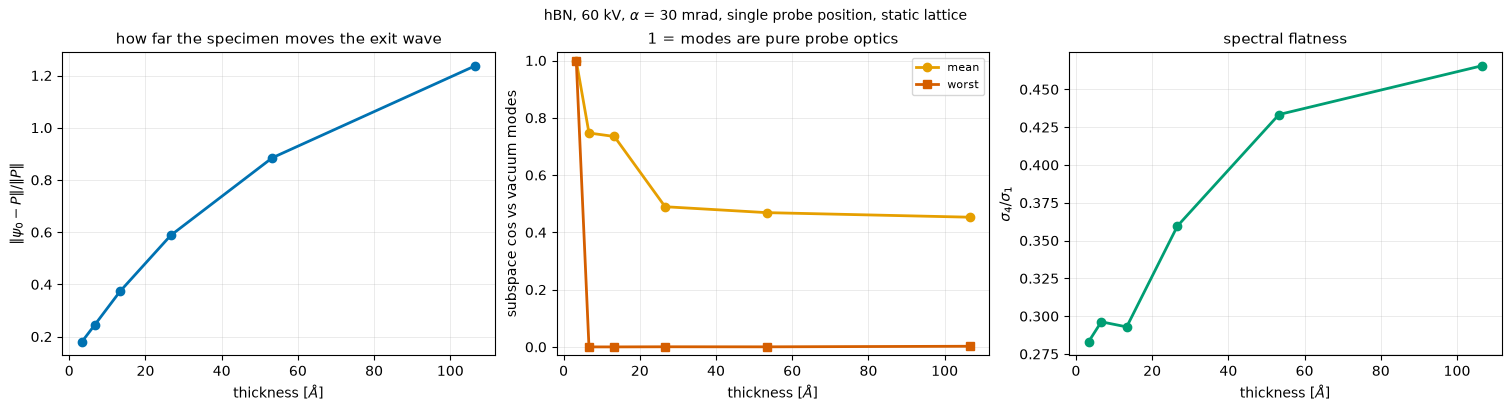

In [8]:
thickness_ang = np.array([e["thickness_ang"] for e in sweep])
object_strength = np.array([e["object_strength"] for e in sweep])
min_cosine = np.array([e["subspace_cosines"].min() for e in sweep])
mean_cosine = np.array([e["subspace_cosines"].mean() for e in sweep])
spectral_flatness = np.array([e["singular_values"][-1] / e["singular_values"][0]
                              for e in sweep])

fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.0), constrained_layout=True)

axes[0].plot(thickness_ang, object_strength, marker="o", color="#0072B2", linewidth=2.0)
axes[0].set_xlabel("thickness [$\\AA$]")
axes[0].set_ylabel("$\\|\\psi_0 - P\\| / \\|P\\|$")
axes[0].set_title("how far the specimen moves the exit wave", fontsize=11)

axes[1].plot(thickness_ang, mean_cosine, marker="o", color="#E69F00", linewidth=2.0,
             label="mean")
axes[1].plot(thickness_ang, min_cosine, marker="s", color="#D55E00", linewidth=2.0,
             label="worst")
axes[1].set_xlabel("thickness [$\\AA$]")
axes[1].set_ylabel("subspace cos vs vacuum modes")
axes[1].set_ylim(-0.03, 1.03)
axes[1].set_title("1 = modes are pure probe optics", fontsize=11)
axes[1].legend(fontsize=8)

axes[2].plot(thickness_ang, spectral_flatness, marker="o", color="#009E73", linewidth=2.0)
axes[2].set_xlabel("thickness [$\\AA$]")
axes[2].set_ylabel("$\\sigma_4 / \\sigma_1$")
axes[2].set_title("spectral flatness", fontsize=11)

for ax in axes:
    ax.grid(True, alpha=0.25, linewidth=0.7)
    ax.set_axisbelow(True)
fig.suptitle(
    f"hBN, {ACC_VOLTAGE_EV/1e3:.0f} kV, $\\alpha$ = {PROBE_SEMIANGLE_MRAD:.0f} mrad, "
    f"single probe position, static lattice", fontsize=10)
plt.show()

In [9]:
print(f"{'layers':>7} {'t [A]':>8} {'slices':>7} {'phi_max':>9} {'|psi-P|/|P|':>12} "
      + " ".join(f"{'s' + str(i + 1):>10}" for i in range(N_MODES))
      + f" {'s4/s1':>7} {'mean cos':>9} {'min cos':>8}")
for entry in sweep:
    print(f"{entry['n_layers']:7d} {entry['thickness_ang']:8.2f} {entry['n_slices']:7d} "
          f"{entry['projected_phase_max_rad']:9.3f} {entry['object_strength']:12.3f} "
          + " ".join(f"{v:10.3e}" for v in entry["singular_values"])
          + f" {entry['singular_values'][-1] / entry['singular_values'][0]:7.3f} "
          f"{entry['subspace_cosines'].mean():9.4f} {entry['subspace_cosines'].min():8.4f}")

 layers    t [A]  slices   phi_max  |psi-P|/|P|         s1         s2         s3         s4   s4/s1  mean cos  min cos
      1     3.33       5     0.497        0.181  2.754e-03  2.750e-03  7.911e-04  7.798e-04   0.283    0.9991   0.9984
      2     6.66       7     0.919        0.244  2.620e-03  2.614e-03  9.848e-04  7.762e-04   0.296    0.7470   0.0000
      4    13.32      11     1.838        0.373  2.381e-03  2.375e-03  1.533e-03  6.975e-04   0.293    0.7348   0.0000
      8    26.64      19     3.676        0.588  2.311e-03  2.075e-03  2.074e-03  8.313e-04   0.360    0.4895   0.0004
     16    53.28      35     7.351        0.885  2.603e-03  1.846e-03  1.841e-03  1.128e-03   0.433    0.4689   0.0003
     32   106.56      67    14.703        1.237  2.278e-03  1.628e-03  1.627e-03  1.061e-03   0.466    0.4530   0.0023
